In [1]:
import pandas as pd

# Checking the cloumns and data frame sizes
classification = pd.read_csv(
    "../Data/whole network/classification.csv.gz"
)

coordinates = pd.read_csv(
    "../Data/whole network/coordinates.csv.gz"
)

print("Classification:", classification.shape)
print("Coordinates:", coordinates.shape)

print("\nClassification columns:")
print(classification.columns.tolist())

print("\nCoordinate columns:")
print(coordinates.columns.tolist())

Classification: (139255, 8)
Coordinates: (238909, 3)

Classification columns:
['root_id', 'flow', 'super_class', 'class', 'sub_class', 'hemilineage', 'side', 'nerve']

Coordinate columns:
['root_id', 'position', 'supervoxel_id']


In [2]:
# Separate position into x, y, z
xyz = (
    coordinates["position"]
    .str.strip("[]")
    .str.replace(",", " ", regex=False)
    .str.split(expand=True)
    .astype(float)
)

coordinates["x"] = xyz[0]
coordinates["y"] = xyz[1]
coordinates["z"] = xyz[2]

# Combine neuron positions with classifications
nodes_df = coordinates.merge(
    classification,
    on="root_id",
    how="left"
)

print("Total neurons:", len(nodes_df))
print(nodes_df.head())

Total neurons: 238909
              root_id                position      supervoxel_id         x  \
0  720575940613726179  [352484 175164 229040]  76704474512672967  352484.0   
1  720575940623219453  [631424 216180  55880]  81490235707935665  631424.0   
2  720575940613998790  [713412 223496  57080]  82897679310436225  713412.0   
3  720575940606611401  [444928 283372  77240]  78254373054459056  444928.0   
4  720575940620628957  [516764 103356  67880]  79517986792372064  516764.0   

          y         z       flow        super_class                 class  \
0  175164.0  229040.0  intrinsic  visual_projection                   NaN   
1  216180.0   55880.0  intrinsic            central                   NaN   
2  223496.0   57080.0  intrinsic            central                   NaN   
3  283372.0   77240.0   afferent            sensory        mechanosensory   
4  103356.0   67880.0   efferent          endocrine  pars_intercerebralis   

    sub_class   hemilineage   side nerve  
0  

In [3]:
# Count broad neuron classes
print(nodes_df["super_class"].value_counts())

# Count more specific classes
print(nodes_df["class"].value_counts())

# Check neurons without classification
print("Missing classification:",
      nodes_df["super_class"].isna().sum())

super_class
optic                 123301
central                65592
sensory                24048
visual_projection      14253
descending              4527
ascending               3719
visual_centrifugal      2327
sensory_ascending        690
motor                    319
endocrine                133
Name: count, dtype: int64
class
optic_lobe_intrinsic    122133
visual                   13747
mechanosensory            6710
Kenyon_Cell               6082
CX                        5013
AN                        4282
olfactory                 2901
ALPN                      2264
ALLN                      1389
bilateral                  892
LHLN                       763
DAN                        508
gustatory                  469
MBON                       341
brain_motor_neuron         314
TuBu                       261
unknown_sensory            229
LHCENT                     188
mAL                        140
ocellar                    121
ALIN                       117
hygrosensory   

In [4]:
# Check unique neurons in each file
print("Classification rows:", len(classification))
print("Unique classified neurons:", classification["root_id"].nunique())

print("Coordinate rows:", len(coordinates))
print("Unique coordinate neurons:", coordinates["root_id"].nunique())

# Check the merged data
print("Merged rows:", len(nodes_df))
print("Unique merged neurons:", nodes_df["root_id"].nunique())
print("Duplicate neuron IDs:", nodes_df["root_id"].duplicated().sum())

Classification rows: 139255
Unique classified neurons: 139255
Coordinate rows: 238909
Unique coordinate neurons: 139255
Merged rows: 238909
Unique merged neurons: 139255
Duplicate neuron IDs: 99654


In [5]:
# Find neurons with multiple positions
duplicates = coordinates[
    coordinates.duplicated("root_id", keep=False)
]

# Look at a few examples
print(
    duplicates[
        ["root_id", "position", "supervoxel_id"]
    ].head(15)
)

# Check whether positions are actually different
print(
    "Neurons with multiple distinct positions:",
    coordinates.groupby("root_id")["position"]
    .nunique()
    .gt(1)
    .sum()
)

               root_id                position      supervoxel_id
0   720575940613726179  [352484 175164 229040]  76704474512672967
1   720575940623219453  [631424 216180  55880]  81490235707935665
2   720575940613998790  [713412 223496  57080]  82897679310436225
6   720575940615848788  [437536 290624  81960]  78113773005204743
7   720575940622897639  [515204  92704  88280]  79447480676382111
8   720575940650527222  [517080  94508 108320]  79517849487611135
10  720575940626608401  [613772 334756  75240]  81140384918898864
11  720575940646663044  [572048 206220  29240]  80434498319496396
12  720575940613958194  [475788 415152 254560]  78819522634699278
15  720575940636608142  [570128 198476  20560]  80434360813429418
18  720575940621309934  [304896 269568 267000]  75861630264602893
20  720575940629080394  [345512 269428 266080]  76565317639902034
21  720575940617654818  [442904 289876  74120]  78254510493339424
22  720575940615325607  [244120 225892 227640]  74805343053525370
29  720575

In [6]:
# Keep one position for each neuron
unique_coords = coordinates.drop_duplicates(
    subset="root_id",
    keep="first"
).copy()

# Combine positions and classifications
nodes_df = classification.merge(
    unique_coords,
    on="root_id",
    how="left",
    validate="one_to_one"
)

# Check the results
print("Total neurons:", len(nodes_df))
print("Unique neurons:", nodes_df["root_id"].nunique())

print("\nPopulation counts:")
print(nodes_df["super_class"].value_counts())

Total neurons: 139255
Unique neurons: 139255

Population counts:
super_class
optic                 77873
central               32381
sensory               16938
visual_projection      7684
ascending              1750
descending             1305
sensory_ascending       612
visual_centrifugal      522
motor                   110
endocrine                80
Name: count, dtype: int64


In [7]:
# Count neurons in each population
population_counts = nodes_df["super_class"].value_counts()

print(population_counts)

# Count neurons on each side
print("\nHemisphere counts:")
print(nodes_df["side"].value_counts(dropna=False))

super_class
optic                 77873
central               32381
sensory               16938
visual_projection      7684
ascending              1750
descending             1305
sensory_ascending       612
visual_centrifugal      522
motor                   110
endocrine                80
Name: count, dtype: int64

Hemisphere counts:
side
left      69959
right     69093
center      173
NaN          30
Name: count, dtype: int64


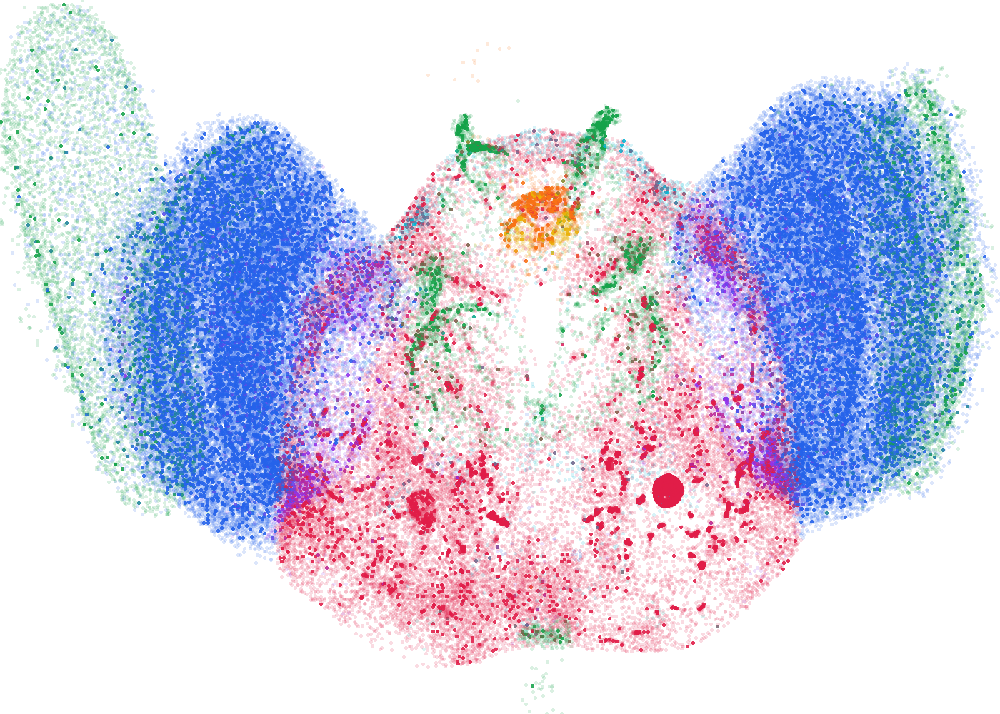

In [8]:
import datashader as ds
import datashader.transfer_functions as tf
from pathlib import Path

# Colors for neuron populations
population_colors = {
    "optic": "#2563eb",
    "central": "#e11d48",
    "sensory": "#16a34a",
    "visual_projection": "#9333ea",
    "ascending": "#f97316",
    "descending": "#06b6d4",
    "sensory_ascending": "#eab308",
    "visual_centrifugal": "#db2777",
    "motor": "#64748b",
    "endocrine": "#14b8a6"
}

# Prepare neurons for coloring
plot_nodes = nodes_df.dropna(subset=["x", "y"]).copy()

plot_nodes["super_class"] = (
    plot_nodes["super_class"].astype("category")
)

# Create canvas using original positions
canvas = ds.Canvas(
    plot_width=1400,
    plot_height=1000,
    x_range=(plot_nodes["x"].min(), plot_nodes["x"].max()),
    y_range=(plot_nodes["y"].min(), plot_nodes["y"].max())
)

# Count neurons by population in each pixel
node_agg = canvas.points(
    plot_nodes,
    "x",
    "y",
    agg=ds.count_cat("super_class")
)

# Color each population
node_img = tf.shade(
    node_agg,
    color_key=population_colors,
    how="eq_hist"
)

# Make neurons easier to see
node_img = tf.spread(node_img, px=2)

# Use a white background
node_img = tf.set_background(node_img, "white")

node_img

In [9]:
# Save prepared neurons for the frontend
nodes_df.to_parquet(
    "../Data/whole network/nodes_population.parquet",
    index=False
)

print("Saved", len(nodes_df), "neurons")

Saved 139255 neurons


In [10]:
# Load existing bundled paths
bundled_edges = pd.read_parquet(
    "../Data/whole network/bundled_edges.parquet"
)

print(bundled_edges.head())
print(bundled_edges.columns.tolist())
print("Total path rows:", len(bundled_edges))

               x              y
0  227091.998708  197976.001809
1  235466.442854  198162.603560
2  242999.817474  198731.195153
3  249435.214587  199732.651000
4  254999.130976  201056.996021
['x', 'y']
Total path rows: 950949693


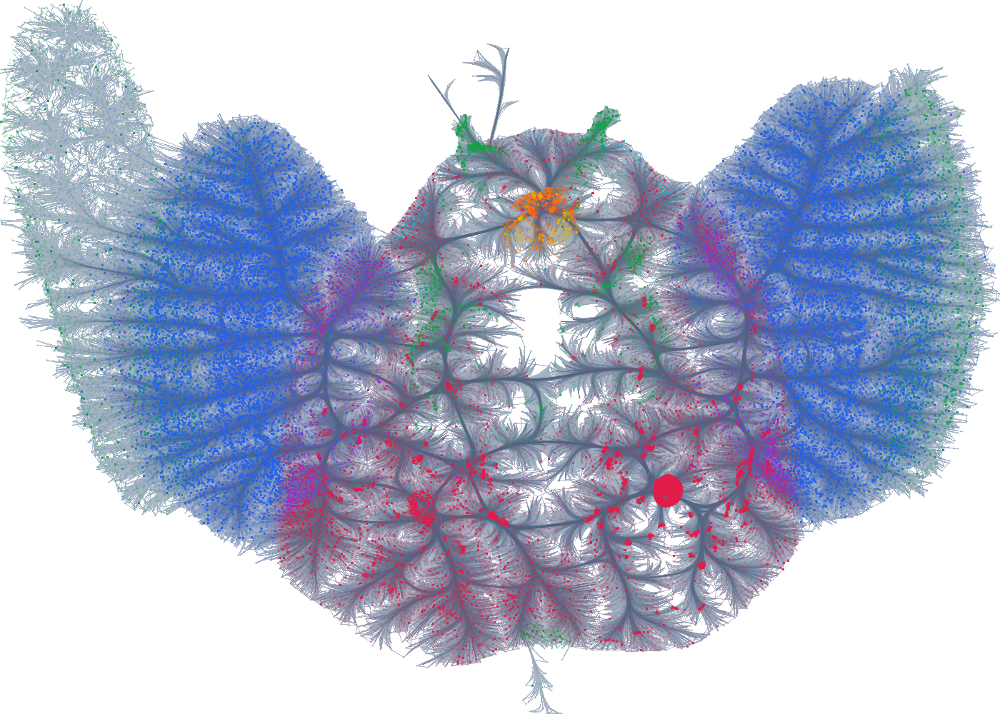

In [11]:
# Draw bundled edges
bundled_agg = canvas.line(
    bundled_edges,
    "x",
    "y",
    agg=ds.count()
)

# Draw darker bundled edges
bundled_img = tf.shade(
    bundled_agg,
    cmap=["#94A3B8", "#1E3A5F"],
    how="eq_hist",
    alpha=200
)

# Color neurons with transparent background
node_overlay = tf.shade(
    node_agg,
    color_key=population_colors,
    how="eq_hist"
)

node_overlay = tf.spread(node_overlay, px=1)

# Put colored neurons over bundled edges
final_img = tf.stack(
    bundled_img,
    node_overlay,
    how="over"
)

# Add white background last
final_img = tf.set_background(final_img, "white")

final_img

In [12]:
# Load existing JO circuit
jo_nodes = pd.read_parquet(
    "../Data/jo circuit/jo_nodes.parquet"
)

jo_edges = pd.read_parquet(
    "../Data/jo circuit/jo_edges.parquet"
)

jo_bundled = pd.read_parquet(
    "../Data/jo circuit/jo_bundled.parquet"
)

print("JO nodes:", len(jo_nodes))
print("JO edges:", len(jo_edges))
print("Bundled paths:", jo_bundled["edge_id"].nunique())

print("\nCell types:")
print(jo_nodes["cell_type"].value_counts())

JO nodes: 723
JO edges: 4608
Bundled paths: 4608

Cell types:
cell_type
JO-B             299
Intermediate     299
JO-A              94
pC2la             15
pC2lb              8
pC2lc              4
pC2ld              2
pC2la / pC2lb      1
pC2la / pC2lc      1
Name: count, dtype: int64


In [13]:
# Prepare whole-brain neurons
whole_nodes = nodes_df.copy()
whole_nodes["root_id"] = whole_nodes["root_id"].astype(str)

# Get JO circuit neuron types
jo_types = jo_nodes[["id", "cell_type"]].copy()
jo_types["id"] = jo_types["id"].astype(str)

jo_types = jo_types.rename(columns={
    "id": "root_id",
    "cell_type": "jo_type"
})

# Match JO neurons with whole-brain neurons
whole_nodes = whole_nodes.merge(
    jo_types,
    on="root_id",
    how="left",
    validate="one_to_one"
)

# Identify neurons belonging to the JO circuit
whole_nodes["is_jo_circuit"] = whole_nodes["jo_type"].notna()

print("Whole network:", len(whole_nodes))
print("JO neurons matched:", whole_nodes["is_jo_circuit"].sum())

# Check their broad classifications
print("\nJO neuron populations:")
print(
    pd.crosstab(
        whole_nodes["jo_type"],
        whole_nodes["super_class"]
    )
)

Whole network: 139255
JO neurons matched: 723

JO neuron populations:
super_class    ascending  central  descending  sensory  visual_centrifugal
jo_type                                                                   
Intermediate          17      260          19        0                   3
JO-A                   0        0           0       94                   0
JO-B                   0        0           0      299                   0
pC2la                  0       15           0        0                   0
pC2la / pC2lb          0        1           0        0                   0
pC2la / pC2lc          0        1           0        0                   0
pC2lb                  0        8           0        0                   0
pC2lc                  0        4           0        0                   0
pC2ld                  0        2           0        0                   0


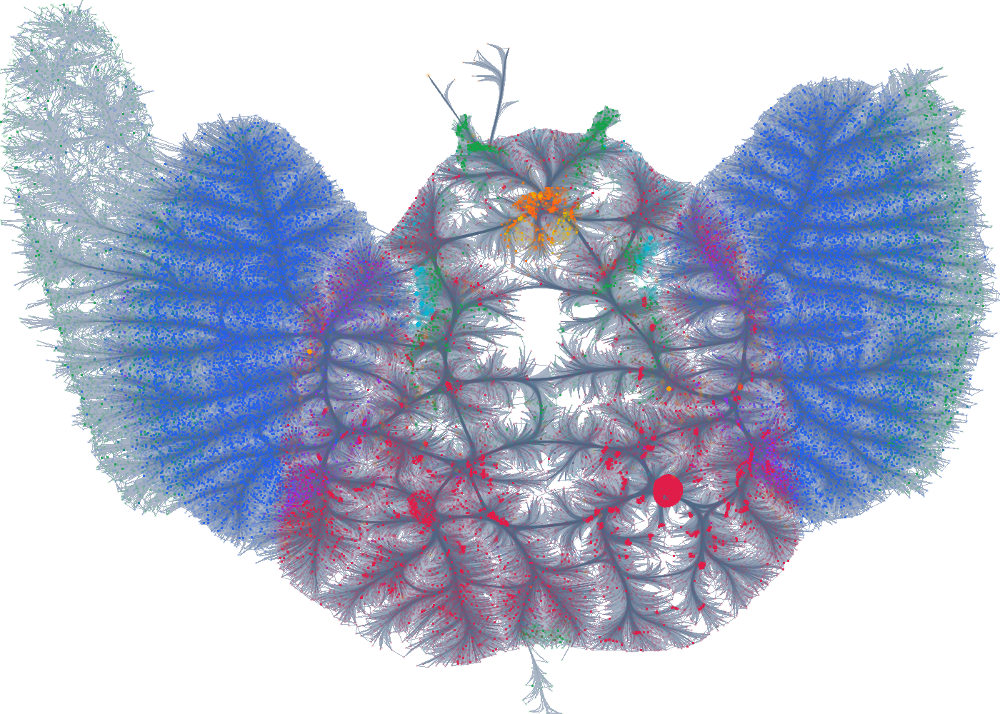

In [14]:
import numpy as np

# Get neurons belonging to the JO circuit
jo_focus = whole_nodes[
    whole_nodes["is_jo_circuit"]
].dropna(subset=["x", "y"]).copy()

# Group specific cell types
jo_focus["circuit_group"] = np.select(
    [
        jo_focus["jo_type"] == "JO-A",
        jo_focus["jo_type"] == "JO-B",
        jo_focus["jo_type"].str.startswith("pC2l", na=False)
    ],
    ["JO-A", "JO-B", "pC2l"],
    default="Intermediate"
)

# Colors for the JO circuit
jo_colors = {
    "JO-A": "#2563EB",
    "JO-B": "#06B6D4",
    "pC2l": "#E11D48",
    "Intermediate": "#F59E0B"
}

# Prepare groups for Datashader
jo_focus["circuit_group"] = (
    jo_focus["circuit_group"].astype("category")
)

# Draw JO circuit neurons
jo_agg = canvas.points(
    jo_focus,
    "x",
    "y",
    agg=ds.count_cat("circuit_group")
)

# Color the circuit neurons
jo_img = tf.shade(
    jo_agg,
    color_key=jo_colors,
    how="linear"
)

# Make highlighted neurons larger
jo_img = tf.spread(jo_img, px=3)

# Overlay on the existing whole-network figure
highlighted_img = tf.stack(
    final_img,
    jo_img,
    how="over"
)

highlighted_img

In [15]:
import pyarrow.parquet as pq

file = pq.ParquetFile(
    "../Data/whole network/bundled_edges.parquet"
)

print("Total rows:", file.metadata.num_rows)
print("Columns:", file.schema.names)
print(next(file.iter_batches(batch_size=6)).to_pandas())

Total rows: 950949693
Columns: ['x', 'y']
               x              y
0  227091.998708  197976.001809
1  235466.442854  198162.603560
2  242999.817474  198731.195153
3  249435.214587  199732.651000
4  254999.130976  201056.996021
5  260365.035332  202637.346696


In [18]:
edges_df = pd.read_csv(
    "../Data/whole network/whole_edges.csv.gz"
)

print(edges_df.shape)
print(edges_df.head())

(22285323, 3)
               source              target  syn_count
0  720575940625363947  720575940623224444         12
1  720575940613354467  720575940616690107          1
2  720575940630432382  720575940618518557         67
3  720575940627314521  720575940626337738         10
4  720575940616775218  720575940632128018          1


In [20]:
import numpy as np
import pandas as pd
from pathlib import Path

# Use neurons already loaded
node_ids = pd.Index(nodes_df["root_id"].astype("int64"))

# Save compact connection indices
output = Path("../Data/whole network/straight_edges.bin")
temp = output.with_suffix(".bin.part")

batch_size = 1_000_000
total_saved = 0

with open(temp, "wb") as file:

    for start in range(0, len(edges_df), batch_size):

        batch = edges_df.iloc[start:start + batch_size]

        # Match connections to neuron positions
        sources = node_ids.get_indexer(batch["source"])
        targets = node_ids.get_indexer(batch["target"])

        # Keep connections with valid neurons
        valid = (sources >= 0) & (targets >= 0)

        # Store source and target indices
        pairs = np.column_stack([
            sources[valid],
            targets[valid]
        ]).astype("<u4")

        pairs.tofile(file)

        total_saved += len(pairs)

        print(
            f"Processed {min(start + batch_size, len(edges_df)):,} / "
            f"{len(edges_df):,}"
        )

temp.replace(output)

print("Connections saved:", total_saved)
print("File size (MB):", round(output.stat().st_size / 1e6, 1))

Processed 1,000,000 / 22,285,323
Processed 2,000,000 / 22,285,323
Processed 3,000,000 / 22,285,323
Processed 4,000,000 / 22,285,323
Processed 5,000,000 / 22,285,323
Processed 6,000,000 / 22,285,323
Processed 7,000,000 / 22,285,323
Processed 8,000,000 / 22,285,323
Processed 9,000,000 / 22,285,323
Processed 10,000,000 / 22,285,323
Processed 11,000,000 / 22,285,323
Processed 12,000,000 / 22,285,323
Processed 13,000,000 / 22,285,323
Processed 14,000,000 / 22,285,323
Processed 15,000,000 / 22,285,323
Processed 16,000,000 / 22,285,323
Processed 17,000,000 / 22,285,323
Processed 18,000,000 / 22,285,323
Processed 19,000,000 / 22,285,323
Processed 20,000,000 / 22,285,323
Processed 21,000,000 / 22,285,323
Processed 22,000,000 / 22,285,323
Processed 22,285,323 / 22,285,323
Connections saved: 22285323
File size (MB): 178.3
